# Demo kết quả Huy — bản bàn giao

Chỉ đọc kết quả đã chốt, đối chiếu CSV gốc; không fit lại, không tune test. Hàn tích hợp vào demo cuối của nhóm. Mục tiêu toàn demo 5 phút, không coi đây là đã diễn tập.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
sys.path.insert(0,str(ROOT))
from src.residual_tasks import load_checked_predictions, metrics
config, comparison, predictions, selected=load_checked_predictions(ROOT)
print('Protocol:',config['protocol_id'],'Selected by CV:',selected)
display(comparison[['model_id','cv_mse_mean','test_mse','test_rmse','test_mae','test_r2']])

Protocol: ie313_raw_v1_seed0_cv5 Selected by CV: M3


,model_id,cv_mse_mean,test_mse,test_rmse,test_mae,test_r2
0,M0,104402.753571,120131.607928,346.600069,144.857174,-0.000010
1,M1,99919.961727,115888.690541,340.424280,137.116888,0.035309
2,M2,79988.148575,97964.136704,312.992231,103.763734,0.184518
3,M3,79227.997866,97156.549919,311.699454,102.024557,0.191241
4,M4,79988.147660,97963.935381,312.991909,103.761672,0.184520


## Sai số thật và nhóm quan sát

Định nghĩa phần dư actual−predicted; nhóm phải kèm n. Shared room ít mẫu. 167 dự đoán âm giữ nguyên; RMSE lớn hơn MAE do bình phương nhấn mạnh sai số lớn.

,grouping,city,n,mse,rmse,mae,r2,mean_residual_actual_minus_predicted,median_abs_residual,p90_abs_residual,negative_predictions,room_type,day_type
10,room_type,NaN,6508,144401.403392,380.001847,109.529154,0.170190,2.332876,68.344133,199.495735,15,Entire home/apt,NaN
11,room_type,NaN,3758,16978.743803,130.302509,89.003635,0.108699,-6.305896,75.141896,163.399175,143,Private room,NaN
12,room_type,NaN,76,16086.668078,126.833229,103.244386,-0.763903,4.476027,97.798604,186.188089,9,Shared room,NaN
13,day_type,NaN,5120,152937.903640,391.072760,104.349857,0.119664,0.999590,70.518283,187.942347,90,NaN,weekdays
14,day_type,NaN,5222,42464.759216,206.069792,99.744676,0.371574,-2.545561,71.175865,186.044479,77,NaN,weekends


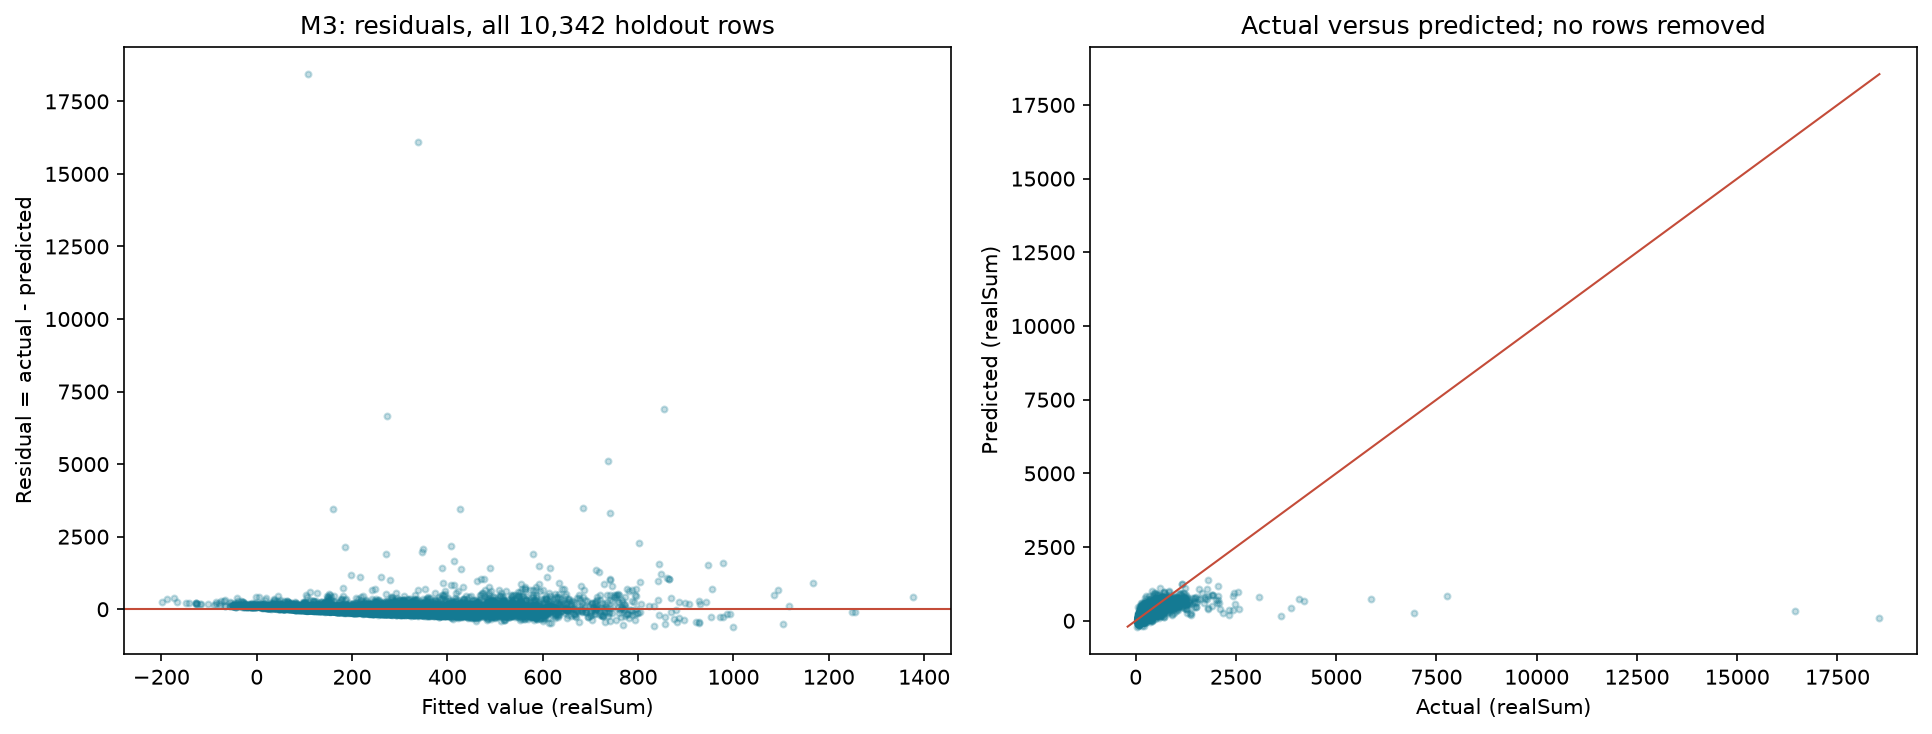

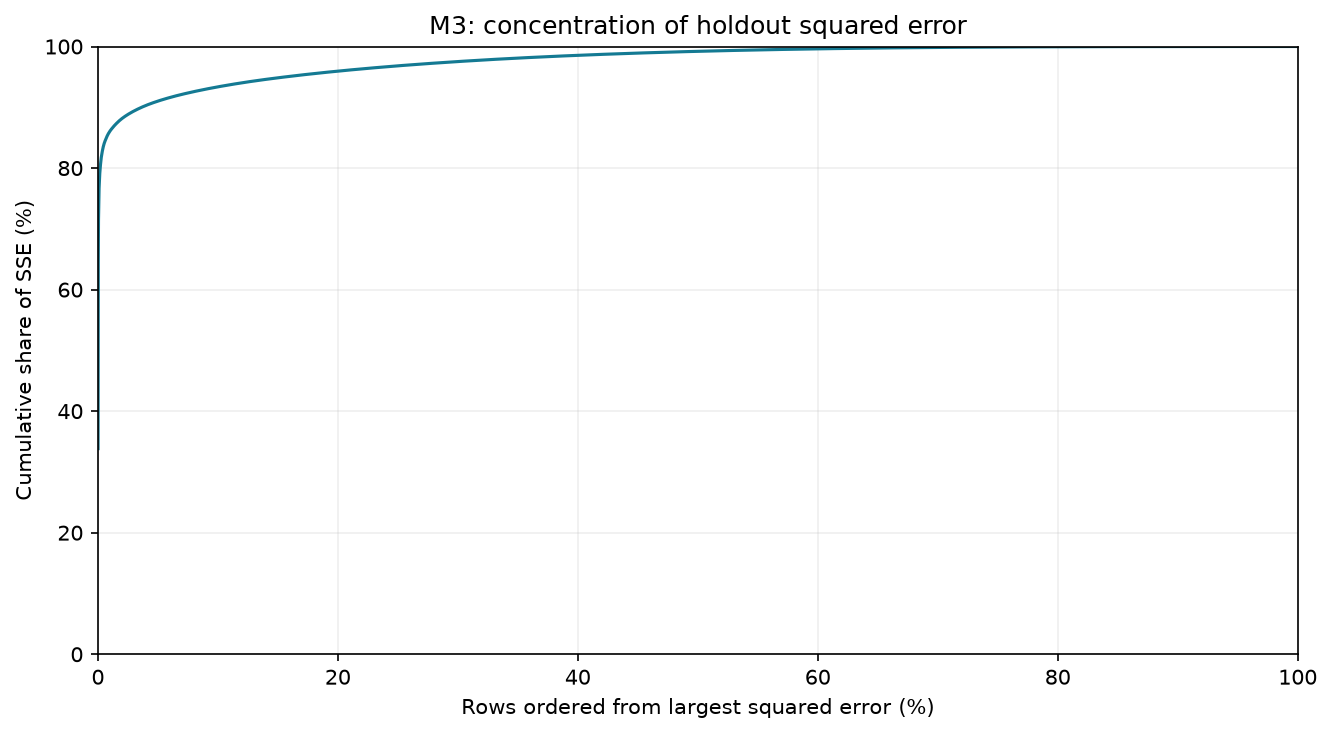

In [2]:
groups=pd.read_csv(ROOT/'outputs/tables/b_residual_group_metrics.csv')
display(groups.loc[groups.grouping.isin(['room_type','day_type'])])
display(Image(filename=str(ROOT/'outputs/figures/b_08_residual_and_actual_predicted.png')))
display(Image(filename=str(ROOT/'outputs/figures/b_10_residual_error_concentration.png')))

## Truy vết một trường hợp sai số lớn

File/dòng được đối chiếu với dữ liệu gộp; source_row không mặc định số dòng Excel hay listing ID. Không suy từ lỗi lớn sang gian lận, giá sai hoặc căn hộ hạng sang.

In [3]:
cases=pd.read_csv(ROOT/'outputs/tables/b_residual_cases.csv')
case=cases.iloc[0]
trace=predictions.loc[predictions.model_id.eq(selected)&predictions.source_file.eq(case.source_file)&predictions.source_row.eq(case.source_row)]
assert len(trace)==1
assert abs(trace.iloc[0].actual-case.actual)<1e-8
display(trace[config['trace_keys']+['city','day_type','room_type','person_capacity','bedrooms','dist','actual','predicted','residual']])
print('Checked: predicted record matches holdout source keys and actual value')

,source_file,source_row,city,day_type,room_type,person_capacity,bedrooms,dist,actual,predicted,residual
31719,athens_weekdays.csv,1510,athens,weekdays,Entire home/apt,2.0,1,1.196536,18545.450285,106.882053,18438.568232


Checked: predicted record matches holdout source keys and actual value
